In [ ]:
!pip install -q torch torchaudio transformers librosa soundfile scikit-learn matplotlib

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!unzip -q /content/drive/MyDrive/LA.zip -d /content/

Mounted at /content/drive


In [ ]:
%%writefile /content/prepare_asvspoof.py
import argparse, os, shutil, numpy as np

PROTOCOL_MAP = {
    "train": "ASVspoof2019.LA.cm.train.trn.txt",
    "dev": "ASVspoof2019.LA.cm.dev.trl.txt",
    "eval": "ASVspoof2019.LA.cm.eval.trl.txt",
}
FLAC_DIR_MAP = {
    "train": "ASVspoof2019_LA_train/flac",
    "dev": "ASVspoof2019_LA_dev/flac",
    "eval": "ASVspoof2019_LA_eval/flac",
}

def parse_protocol(path):
    entries = []
    with open(path) as f:
        for line in f:
            parts = line.strip().split()
            entries.append((parts[0], parts[1], parts[-1]))
    return entries

def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--root", required=True)
    parser.add_argument("--out", required=True)
    parser.add_argument("--max-per-class", type=int, default=None)
    args = parser.parse_args()

    for split in ("train", "dev", "eval"):
        # Automatically detect folder name for protocols
        proto_dir = os.path.join(args.root, "ASVspoof2019_LA_cm_protocols")
        if not os.path.isdir(proto_dir):
            proto_dir = os.path.join(args.root, "LA_cm_protocols")

        proto_path = os.path.join(proto_dir, PROTOCOL_MAP[split])

        # Automatically detect flac audio directory
        flac_dir = os.path.join(args.root, FLAC_DIR_MAP[split])
        if not os.path.isdir(flac_dir):
            alt_dir = os.path.join(args.root, f"ASVspoof2019_LA_{split}")
            if os.path.isdir(alt_dir):
                flac_dir = alt_dir

        entries = parse_protocol(proto_path)
        counts = {"real": 0, "fake": 0}
        for _, utt_id, label in entries:
            cls = "real" if label == "bonafide" else "fake"
            if args.max_per_class and counts[cls] >= args.max_per_class:
                continue
            src = os.path.join(flac_dir, f"{utt_id}.flac")
            if not os.path.isfile(src):
                continue
            dst_dir = os.path.join(args.out, split, cls)
            os.makedirs(dst_dir, exist_ok=True)
            shutil.copy2(src, os.path.join(dst_dir, f"{utt_id}.flac"))
            counts[cls] += 1
        print(f"{split}: real={counts['real']}, fake={counts['fake']}")
    print("Done.")

if __name__ == "__main__":
    main()

Overwriting /content/prepare_asvspoof.py


In [ ]:
!python /content/prepare_asvspoof.py \
    --root /content/LA \
    --out /content/asvspoof_ready \
    --max-per-class 2000

train: real=2000, fake=2000
dev: real=2000, fake=2000
eval: real=2000, fake=2000
Done.


In [ ]:
import os, torch, librosa, numpy as np
from torch.utils.data import Dataset, DataLoader

TARGET_SR = 16000
MAX_SAMPLES = TARGET_SR * 4  # 4 seconds

class ASVspoofDataset(Dataset):
    def __init__(self, root_dir, split="train"):
        self.samples = []
        for label_name, label_id in [("real", 0), ("fake", 1)]:
            class_dir = os.path.join(root_dir, split, label_name)
            if not os.path.isdir(class_dir):
                continue
            for fname in os.listdir(class_dir):
                self.samples.append((os.path.join(class_dir, fname), label_id))
        np.random.shuffle(self.samples)

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        wav, _ = librosa.load(path, sr=TARGET_SR, mono=True)
        if len(wav) > MAX_SAMPLES:
            start = np.random.randint(0, len(wav) - MAX_SAMPLES)
            wav = wav[start : start + MAX_SAMPLES]
        else:
            wav = np.pad(wav, (0, max(0, MAX_SAMPLES - len(wav))))
        return torch.tensor(wav, dtype=torch.float32), label

print("Dataset class ready ✅")

Dataset class ready ✅


In [ ]:
import torch.nn as nn
from transformers import Wav2Vec2Model

class AudioClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = Wav2Vec2Model.from_pretrained(
            "facebook/wav2vec2-base", output_hidden_states=False,
        )
        self.backbone.freeze_feature_encoder()
        self.head = nn.Sequential(
            nn.Linear(768, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 2),
        )

    def forward(self, waveform):
        features = self.backbone(waveform).last_hidden_state
        pooled = features.mean(dim=1)
        return self.head(pooled)

print("Model class ready ✅")

Model class ready ✅


In [ ]:
DATA_ROOT = "/content/asvspoof_ready"
EPOCHS = 5
BATCH_SIZE = 8
LR = 1e-5

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {device}")

train_ds = ASVspoofDataset(DATA_ROOT, "train")
dev_ds = ASVspoofDataset(DATA_ROOT, "dev")
print(f"Train: {len(train_ds)}, Dev: {len(dev_ds)}")

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
dev_loader = DataLoader(dev_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

model = AudioClassifier().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR)
criterion = nn.CrossEntropyLoss()

history = {"train_loss": [], "val_loss": [], "val_acc": []}

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0
    for batch_wav, batch_label in train_loader:
        batch_wav, batch_label = batch_wav.to(device), batch_label.to(device)
        optimizer.zero_grad()
        logits = model(batch_wav)
        loss = criterion(logits, batch_label)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    avg_train = total_loss / len(train_loader)

    model.eval()
    val_loss, correct, total = 0, 0, 0
    with torch.no_grad():
        for bw, bl in dev_loader:
            bw, bl = bw.to(device), bl.to(device)
            logits = model(bw)
            val_loss += criterion(logits, bl).item()
            correct += (logits.argmax(1) == bl).sum().item()
            total += bl.size(0)

    avg_val = val_loss / len(dev_loader)
    val_acc = correct / total
    history["train_loss"].append(avg_train)
    history["val_loss"].append(avg_val)
    history["val_acc"].append(val_acc)

    print(f"Epoch {epoch+1}/{EPOCHS}  train_loss={avg_train:.4f}  val_loss={avg_val:.4f}  val_acc={val_acc:.4f}")

Device: cuda
Train: 4000, Dev: 4000


config.json:   0%|          | 0.00/1.84k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  380MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     |  | 
-----------------------------+------------+--+-
project_hid.weight           | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors: reconstructing file:   0%|          |  0.00B /  380MB            

model.safetensors: downloading bytes:           |  0.00B            

Epoch 1/5  train_loss=0.1063  val_loss=0.0113  val_acc=1.0000
Epoch 2/5  train_loss=0.0091  val_loss=0.0034  val_acc=1.0000
Epoch 3/5  train_loss=0.0035  val_loss=0.0015  val_acc=1.0000
Epoch 4/5  train_loss=0.0206  val_loss=0.0031  val_acc=0.9998
Epoch 5/5  train_loss=0.0119  val_loss=0.0106  val_acc=0.9982


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

model.eval()
all_true, all_prob = [], []
with torch.no_grad():
    for bw, bl in dev_loader:
        bw = bw.to(device)
        logits = model(bw)
        probs = torch.softmax(logits, dim=1)[:, 1]
        all_true.extend(bl.numpy())
        all_prob.extend(probs.cpu().numpy())

all_true = np.array(all_true)
all_pred = (np.array(all_prob) >= 0.5).astype(int)

print("=" * 56)
print("TEST SET EVALUATION")
print("=" * 56)
print(classification_report(all_true, all_pred, target_names=["real", "fake"]))
print("Confusion Matrix:")
print(confusion_matrix(all_true, all_pred))

TEST SET EVALUATION
              precision    recall  f1-score   support

        real       1.00      1.00      1.00      2000
        fake       1.00      1.00      1.00      2000

    accuracy                           1.00      4000
   macro avg       1.00      1.00      1.00      4000
weighted avg       1.00      1.00      1.00      4000

Confusion Matrix:
[[1993    7]
 [   0 2000]]


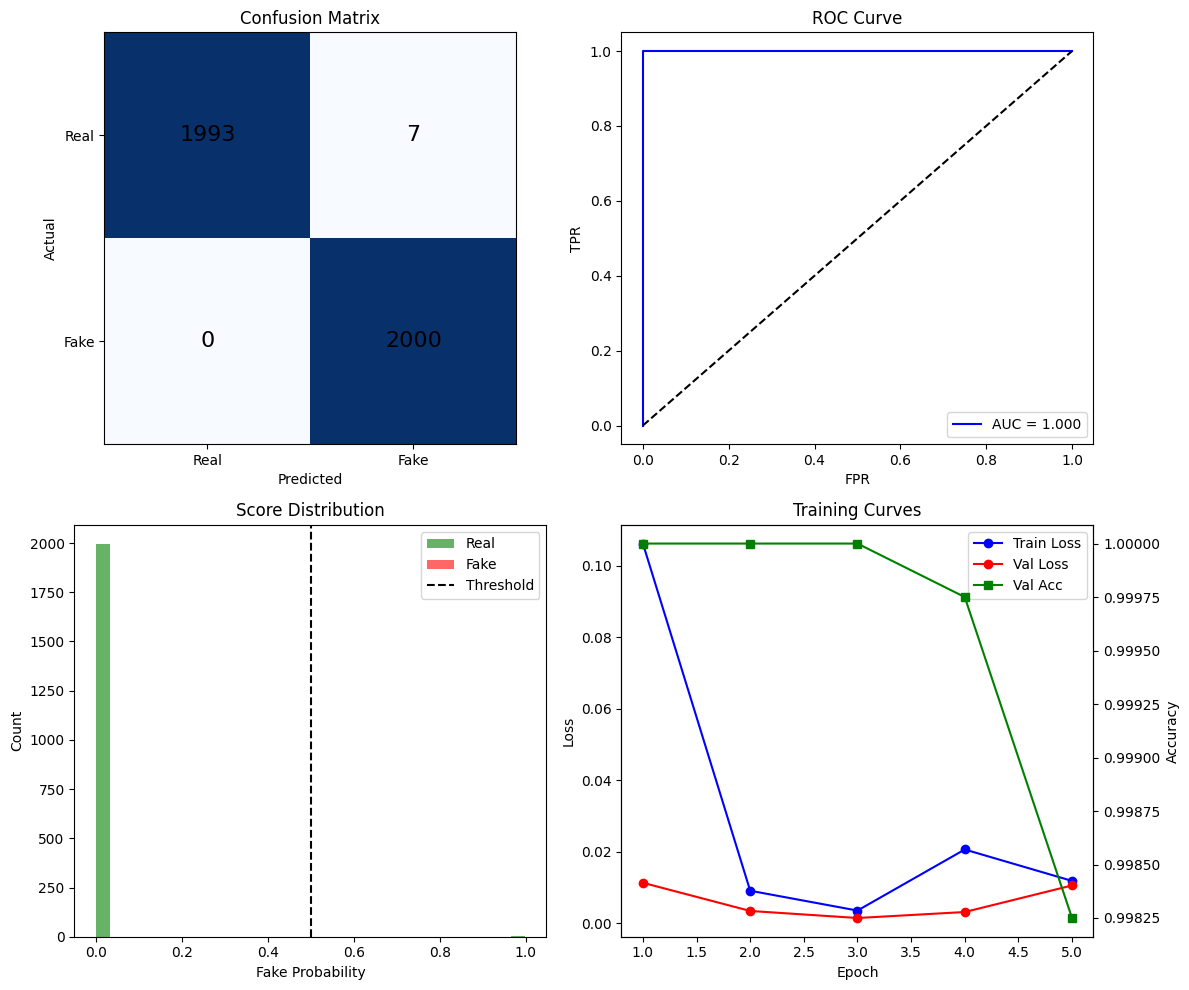

Saved: MyDrive/audio_eval_plots.png ✅


In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Confusion matrix
cm = confusion_matrix(all_true, all_pred)
axes[0,0].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        axes[0,0].text(j, i, str(cm[i][j]), ha="center", va="center", fontsize=16)
axes[0,0].set_xticks([0,1]); axes[0,0].set_xticklabels(["Real","Fake"])
axes[0,0].set_yticks([0,1]); axes[0,0].set_yticklabels(["Real","Fake"])
axes[0,0].set_xlabel("Predicted"); axes[0,0].set_ylabel("Actual")
axes[0,0].set_title("Confusion Matrix")

# ROC curve
fpr, tpr, _ = roc_curve(all_true, all_prob)
roc_auc = auc(fpr, tpr)
axes[0,1].plot(fpr, tpr, "b-", label=f"AUC = {roc_auc:.3f}")
axes[0,1].plot([0,1],[0,1],"k--")
axes[0,1].set_xlabel("FPR"); axes[0,1].set_ylabel("TPR")
axes[0,1].set_title("ROC Curve"); axes[0,1].legend()

# Score distribution
real_s = np.array(all_prob)[all_true == 0]
fake_s = np.array(all_prob)[all_true == 1]
axes[1,0].hist(real_s, bins=30, alpha=0.6, label="Real", color="green")
axes[1,0].hist(fake_s, bins=30, alpha=0.6, label="Fake", color="red")
axes[1,0].axvline(0.5, color="black", linestyle="--", label="Threshold")
axes[1,0].set_xlabel("Fake Probability"); axes[1,0].set_ylabel("Count")
axes[1,0].set_title("Score Distribution"); axes[1,0].legend()

# Training curves
ep = range(1, EPOCHS + 1)
axes[1,1].plot(ep, history["train_loss"], "b-o", label="Train Loss")
axes[1,1].plot(ep, history["val_loss"], "r-o", label="Val Loss")
ax2 = axes[1,1].twinx()
ax2.plot(ep, history["val_acc"], "g-s", label="Val Acc")
axes[1,1].set_xlabel("Epoch"); axes[1,1].set_ylabel("Loss"); ax2.set_ylabel("Accuracy")
axes[1,1].set_title("Training Curves")
l1, lb1 = axes[1,1].get_legend_handles_labels()
l2, lb2 = ax2.get_legend_handles_labels()
axes[1,1].legend(l1+l2, lb1+lb2)

plt.tight_layout()
plt.savefig("/content/drive/MyDrive/audio_eval_plots.png", dpi=150)
plt.show()
print("Saved: MyDrive/audio_eval_plots.png ✅")

In [ ]:
state = model.state_dict()
torch.save(state, "/content/drive/MyDrive/audio_clf.pth")
sz = os.path.getsize("/content/drive/MyDrive/audio_clf.pth") / (1024*1024)
print(f"✅ Saved to Google Drive: MyDrive/audio_clf.pth ({sz:.1f} MB)")

✅ Saved to Google Drive: MyDrive/audio_clf.pth (360.5 MB)
